# Cluster Attribution Workspace

Load existing wallet clusters and compute aggregate inflow sums as a starting point for future insider-type attribution.


In [1]:
from __future__ import annotations

import json
from pathlib import Path
from typing import Dict, List

try:
    import pandas as pd  # type: ignore
except ImportError:
    pd = None

def resolve_data_dir() -> Path:
    search = [Path.cwd()] + list(Path.cwd().parents)
    for base in search:
        if (base / 'sui_insiders' / 'data').exists():
            return (base / 'sui_insiders' / 'data').resolve()
        if base.name == 'sui_insiders' and (base / 'data').exists():
            return (base / 'data').resolve()
        if (base / 'data').exists() and (base / 'scripts').exists():
            return (base / 'data').resolve()
    return (Path.cwd() / 'data').resolve()

DATA_DIR = resolve_data_dir()
print(f'Data directory: {DATA_DIR}')

CLUSTER_JSON_PATH = DATA_DIR / 'cluster_results.json'
if not CLUSTER_JSON_PATH.exists():
    raise FileNotFoundError(f'Missing cluster JSON: {CLUSTER_JSON_PATH}')

with CLUSTER_JSON_PATH.open('r', encoding='utf-8') as fh:
    CLUSTER_RESULTS: Dict[str, Dict[str, object]] = json.load(fh)

print(f'Loaded {len(CLUSTER_RESULTS)} clusters.')


Data directory: /Users/kevincai/Library/Mobile Documents/com~apple~CloudDocs/Career/Interviews/scimitar_capital/sui_insiders/data
Loaded 165 clusters.


In [2]:
def cluster_summary_rows(cluster_results: Dict[str, Dict[str, object]]) -> List[Dict[str, object]]:
    rows: List[Dict[str, object]] = []
    for seed_wallet, summary in cluster_results.items():
        rows.append({
            'seed_wallet': seed_wallet,
            'cluster_size': summary.get('cluster_size', 0),
            'total_cluster_inflow_sui': summary.get('total_cluster_inflow_sui', 0.0),
            'direct_cex_total_sui': summary.get('direct_cex_total_sui', 0.0),
            'direct_cex_tx_count': len(summary.get('direct_cex_transfers', [])),
        })
    return rows

SUMMARY_ROWS = cluster_summary_rows(CLUSTER_RESULTS)
print(f'Summary rows: {len(SUMMARY_ROWS)}')

if pd is not None and SUMMARY_ROWS:
    summary_df = pd.DataFrame(SUMMARY_ROWS).sort_values('total_cluster_inflow_sui', ascending=False)
    display(summary_df)
else:
    for row in SUMMARY_ROWS:
        print(row)


Summary rows: 165


,seed_wallet,cluster_size,total_cluster_inflow_sui,direct_cex_total_sui,direct_cex_tx_count
88,0xcf30da961e1d310546f4df6dcbac0ace091852c77ed2...,3,1.615770e+07,0.0,0
84,0x63fbe037f5cca825dbb66db0464b34ece8ad64413cc0...,3,1.615770e+07,0.0,0
85,0xecad8b6df613da99ebb12a2d42dffc61503628f0170d...,3,1.615770e+07,0.0,0
8,0xab73ad38c63f83eda02182422b545395be1d3caeb54b...,81,4.431998e+06,0.0,0
38,0x8b302e06dd0bc3e09f1e009e1dc32a04f6b4b75ab550...,31,4.360950e+06,0.0,0
...,...,...,...,...,...
74,0xb53a1af6c90f0f023bf93308ea87a934267933ff9cf9...,1,2.213814e+03,0.0,0
13,0x570f39c18f08d5fad6de7dff90a9477c5046d4d0b671...,1,2.063879e+03,0.0,0
106,0x41c4ef00a0b21a25f4fe746aceb2a458109fb4822083...,1,2.033765e+03,0.0,0
19,0x6cd00b0ccb13fe511776c8936af4ae74360de2f475d6...,3,1.576047e+03,0.0,0


In [3]:
total_inflow_all = sum(row['total_cluster_inflow_sui'] for row in SUMMARY_ROWS)
print(f'Total inflow across all clusters: {total_inflow_all:.2f} SUI')

if pd is not None and SUMMARY_ROWS:
    top_n = min(20, len(SUMMARY_ROWS))
    print('Top clusters by total inflow:')
    display(summary_df.head(top_n))


Total inflow across all clusters: 171541916.93 SUI
Top clusters by total inflow:


,seed_wallet,cluster_size,total_cluster_inflow_sui,direct_cex_total_sui,direct_cex_tx_count
88,0xcf30da961e1d310546f4df6dcbac0ace091852c77ed2...,3,1.615770e+07,0.0,0
84,0x63fbe037f5cca825dbb66db0464b34ece8ad64413cc0...,3,1.615770e+07,0.0,0
85,0xecad8b6df613da99ebb12a2d42dffc61503628f0170d...,3,1.615770e+07,0.0,0
8,0xab73ad38c63f83eda02182422b545395be1d3caeb54b...,81,4.431998e+06,0.0,0
38,0x8b302e06dd0bc3e09f1e009e1dc32a04f6b4b75ab550...,31,4.360950e+06,0.0,0
147,0x1c9deef7e10b88cca4211e5d688bb496d6843d916948...,1,3.962700e+06,0.0,0
105,0xcd905a5e5e21c07fcdf275588012e5248bcf3a535eff...,137,3.757480e+06,0.0,0
134,0x2e4706e435195185d69597fdb69bcab9e57a0fa297a1...,15,3.718490e+06,0.0,0
28,0x344fb28d6b69274ec2ca62ccd40ef03eb01cec68495d...,1,3.718354e+06,0.0,0
4,0x935029ca5219502a47ac9b69f556ccf6e2198b5e7815...,147,3.710841e+06,0.0,0


## Next Steps

- Add attribution logic to classify each cluster (e.g., early investor, team wallet, foundation).
- Incorporate manual labels or heuristics (tagged addresses, participation history, etc.).
- Enrich clusters with outbound patterns (CEX routes, DeFi interaction) for stronger attribution signals.


In [4]:
import csv

unlock_totals = []
for csv_path in sorted(DATA_DIR.glob('*_unlock.csv')):
    total_sui = 0.0
    labels = set()
    with csv_path.open('r', encoding='utf-8') as fh:
        reader = csv.DictReader(fh)
        for row in reader:
            try:
                total_sui += float(row.get('amount_sui', 0) or 0)
            except (TypeError, ValueError):
                continue
            label = row.get('event_label')
            if label:
                labels.add(label)
    unlock_totals.append({
        'unlock_file': csv_path.name,
        'total_sui': total_sui,
        'event_labels': sorted(labels),
    })

if unlock_totals:
    unlock_totals.sort(key=lambda x: x['unlock_file'])
    print(f'Unlock files analysed: {len(unlock_totals)}')
    if pd is not None:
        totals_df = pd.DataFrame(unlock_totals)
        display(totals_df)
    else:
        for entry in unlock_totals:
            print(entry)
else:
    print('No unlock CSV files found matching pattern *_unlock.csv')


Unlock files analysed: 6


,unlock_file,total_sui,event_labels
0,2024_05_02_unlock.csv,8.172613e+06,[2024-05-02 Unlock]
1,2024_06_02_unlock.csv,2.375510e+06,[2024-06-02 Unlock]
2,2024_07_02_unlock.csv,1.941468e+06,[2024-07-02 Unlock]
3,2024_08_01_unlock.csv,4.608061e+06,[2024-08-01 Unlock]
4,2024_09_01_unlock.csv,3.607067e+06,[2024-09-01 Unlock]
5,2024_10_01_unlock.csv,5.273521e+06,[2024-10-01 Unlock]


In [5]:
from collections import defaultdict
import csv

unlock_files = sorted(DATA_DIR.glob('*_unlock.csv'))
address_occurrences = defaultdict(set)

for csv_path in unlock_files:
    with csv_path.open('r', encoding='utf-8') as fh:
        reader = csv.DictReader(fh)
        for row in reader:
            addr = row.get('recipient_address')
            if addr:
                address_occurrences[addr].add(csv_path.name)

repeated_addresses_list = [
    {
        'recipient_address': addr,
        'unlock_files': sorted(list(files)),
        'occurrences': len(files),
    }
    for addr, files in address_occurrences.items()
    if len(files) > 1
]

if repeated_addresses_list:
    print(f'Repeated recipient addresses: {len(repeated_addresses_list)}')
    if pd is not None:
        repeated_addresses_df = pd.DataFrame(repeated_addresses_list).sort_values('occurrences', ascending=False)
        display(repeated_addresses_df)
    else:
        repeated_addresses_df = repeated_addresses_list
        for entry in repeated_addresses_list:
            print(entry)
else:
    repeated_addresses_df = pd.DataFrame(columns=['recipient_address', 'unlock_files', 'occurrences']) if pd is not None else []
    print('No repeated recipient addresses found across unlock CSV files.')


Repeated recipient addresses: 128


,recipient_address,unlock_files,occurrences
10,0xe9dfdf59527ef04168dc867e933a36d563b96b942541...,"[2024_05_02_unlock.csv, 2024_06_02_unlock.csv,...",6
11,0x554a09303eb2163d33ce174702d4c6e90cbbc23d804a...,"[2024_05_02_unlock.csv, 2024_06_02_unlock.csv,...",6
22,0x6d07e17dbb66a5de14aa3e05b7f03bad0380e6a8f87c...,"[2024_05_02_unlock.csv, 2024_06_02_unlock.csv,...",6
18,0x9e36bddae68bb180961fda0abdad148c2a25307d2ee9...,"[2024_05_02_unlock.csv, 2024_06_02_unlock.csv,...",6
16,0x669f5681a4cf98f170d2418d848ad9c4847195a8f1be...,"[2024_05_02_unlock.csv, 2024_06_02_unlock.csv,...",6
...,...,...,...
76,0xa9235d166c83484589b81e2e948260a9fbfbbc37981e...,"[2024_06_02_unlock.csv, 2024_07_02_unlock.csv]",2
77,0x7e370553a68568c0729e7c45734ebe68193ee26c098b...,"[2024_06_02_unlock.csv, 2024_10_01_unlock.csv]",2
80,0xcd05b756c0a2ed58d30c4332fc4392ce1c5c23c48491...,"[2024_06_02_unlock.csv, 2024_07_02_unlock.csv]",2
86,0x174d2200947ca8edc4b736d420283b4394d62736583d...,"[2024_06_02_unlock.csv, 2024_10_01_unlock.csv]",2


unlock_file,2024_05_02_unlock.csv,2024_06_02_unlock.csv,2024_07_02_unlock.csv,2024_08_01_unlock.csv,2024_09_01_unlock.csv,2024_10_01_unlock.csv
recipient_address,,,,,,
0xecad8b6df613da99ebb12a2d42dffc61503628f0170d3d4b0242a6eda60c6d56,0.000000e+00,4.942139e+05,7.415088e+05,7.213136e+05,1.331243e+06,1.081593e+06
0x07421ae8fa97d33c2165515430f41ecab5b547f807f12256b07965b78c9f15dc,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.344484e+05,2.521084e+06
0xcf30da961e1d310546f4df6dcbac0ace091852c77ed272d658030ff2be503481,0.000000e+00,5.026170e+05,8.949964e+04,1.005879e+06,2.207349e+05,4.318482e+05
0x1c9deef7e10b88cca4211e5d688bb496d6843d9169488d597b134a4d1103c4b8,0.000000e+00,0.000000e+00,0.000000e+00,5.956514e+05,1.087873e+06,0.000000e+00
0x258dc8a75c7d276134150a25ec70cee986742de5de9748aee0cb3538c177bb8b,0.000000e+00,0.000000e+00,3.007960e+05,3.999781e+05,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...
0xdbec4522d221852d876f9b6a670f5d5d4ad3ff92db063ed9775cb02b1d2bf4dd,0.000000e+00,0.000000e+00,0.000000e+00,4.987360e-04,4.987360e-04,0.000000e+00
0x554a09303eb2163d33ce174702d4c6e90cbbc23d804a677a297010f2afc97ebe,4.000000e-09,2.000000e-09,2.000000e-09,1.000000e-09,1.000000e-09,1.000000e-09
0x669f5681a4cf98f170d2418d848ad9c4847195a8f1bef716c007f221bdcac8c1,4.000000e-09,2.000000e-09,2.000000e-09,1.000000e-09,1.000000e-09,1.000000e-09


/var/folders/v5/q3bx4q856vx4772dswhj2k2w0000gn/T/ipykernel_82493/3066165542.py:41: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


<Figure size 1200x600 with 0 Axes>

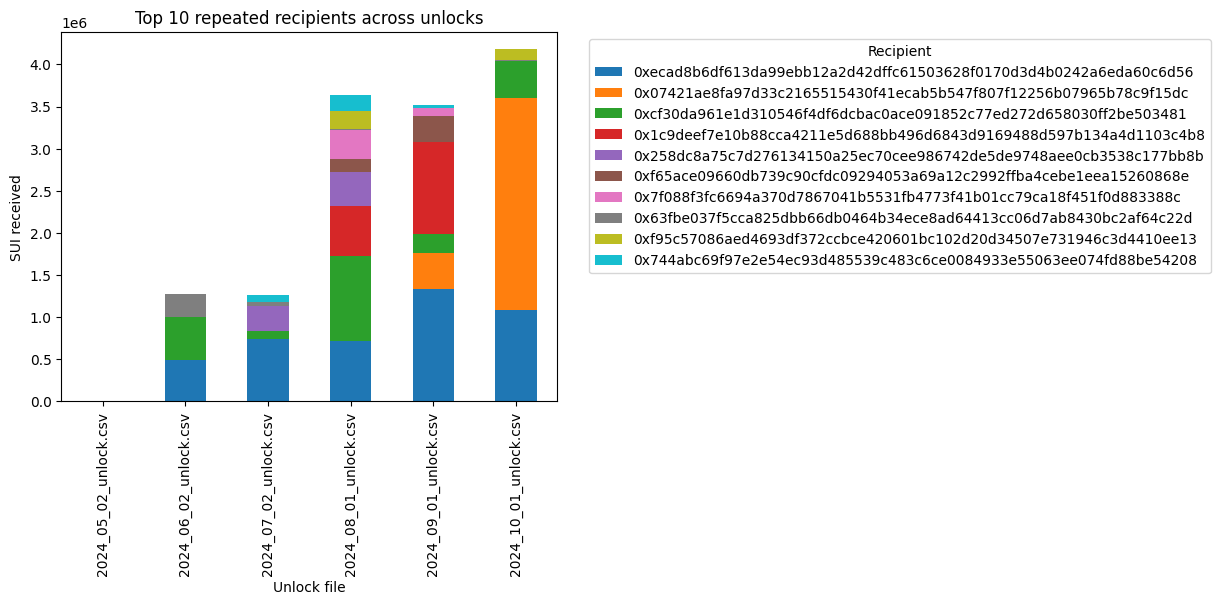

In [6]:
# Aggregate repeated recipient inflows per unlock and chart the top recipients
if pd is None:
    print('pandas is required for repeated recipient aggregation.')
else:
    import matplotlib.pyplot as plt
    transfer_frames = []
    for csv_path in unlock_files:
        df = pd.read_csv(csv_path)
        df['unlock_file'] = csv_path.name
        df['amount_sui'] = pd.to_numeric(df.get('amount_sui'), errors='coerce').fillna(0.0)
        df = df[['unlock_file', 'recipient_address', 'amount_sui']]
        transfer_frames.append(df)
    if transfer_frames:
        transfers_df = pd.concat(transfer_frames, ignore_index=True)
        if isinstance(repeated_addresses_df, pd.DataFrame) and not repeated_addresses_df.empty:
            repeated_set = set(repeated_addresses_df['recipient_address'])
        else:
            repeated_set = {entry['recipient_address'] for entry in repeated_addresses_list} if repeated_addresses_list else set()
        repeated_transfers = transfers_df[transfers_df['recipient_address'].isin(repeated_set)]
        if not repeated_transfers.empty:
            pivot = (
                repeated_transfers.pivot_table(
                    index='recipient_address',
                    columns='unlock_file',
                    values='amount_sui',
                    aggfunc='sum',
                    fill_value=0.0,
                )
            )
            pivot = pivot.assign(total_sui=pivot.sum(axis=1)).sort_values('total_sui', ascending=False)
            pivotWithoutTotal = pivot.drop(columns=['total_sui'])
            display(pivotWithoutTotal)
            top_n = min(10, len(pivot))
            top_pivot = pivot.head(top_n).drop(columns=['total_sui'])
            plt.figure(figsize=(12, 6))
            top_pivot.transpose().plot(kind='bar', stacked=True)
            plt.ylabel('SUI received')
            plt.xlabel('Unlock file')
            plt.title(f'Top {top_n} repeated recipients across unlocks')
            plt.legend(title='Recipient', bbox_to_anchor=(1.05, 1), loc='upper left')
            plt.tight_layout()
            plt.show()
        else:
            print('No transfer rows found for repeated recipients.')
    else:
        print('No unlock CSV data available for aggregation.')
